Question 1

We will be using python for numerically solving for and plotting Black-Scholes IV, as excel would require lots of inefficient goal seeks. We start by importing packages and loading the options data into a pandas dataframe and adding a tau column which is the annualised maturity.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import brentq

raw = pd.read_excel("AMZN_options.xlsx", sheet_name="options", header=None)

options = []

for col in range(1, 6):
    days = raw.iloc[1, col]
    strikes = raw.iloc[3:16, col]
    prices = raw.iloc[17:30, col]

    for strike, price in zip(strikes, prices):
        options.append({
            "days": days,
            "strike": strike,
            "price": price
        })

options = pd.DataFrame(options)
options["tau"] = options["days"]/365
options.head()

,days,strike,price,tau
0,14.0,230.0,30.62,0.038356
1,14.0,235.0,25.67,0.038356
2,14.0,240.0,20.87,0.038356
3,14.0,245.0,16.25,0.038356
4,14.0,250.0,11.94,0.038356


We define the Black-Scholes formula for a call option and let it return the price of the option given parameters. We will use this function when solving for the IV numerically.

In [3]:
def bs_call(S, K, r, tau, sigma):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))
    d2 = d1 - sigma * np.sqrt(tau)

    return S * norm.cdf(d1) - K * np.exp(-r * tau) * norm.cdf(d2)


We also define the function that numerically solves for and returns the IV that makes C_modelprice - C_marketprice = 0.

We use SciPy's brentq to solve for IV, giving it an interval of [0.01%;300%] in annual volatility.

In [4]:
def implied_vol(S, K, r, tau, price):
    def pricing_error(sigma):
        return bs_call(S, K, r, tau, sigma) - price

    return brentq(pricing_error, 0.0001, 3.0)

We run a first test and get an IV of sigma=0.335 which seems reasonable.

If we plug this into our Black-Scholes function we should expect to get back the observed market price. Rounded to two decimals we get exactly the same price, so we conclude that our code works.

In [5]:
S=260
r=0.05
test = options.iloc[0]
iv = implied_vol(S, test["strike"], r, test["tau"],test["price"])
print(iv)

model_price = bs_call(S, test["strike"], r, test["tau"], iv)
print(f"Model price: {model_price:.2f}, market price: {test["price"]}")

0.33539714429219303
Model price: 30.62, market price: 30.62


Do the same for all option maturities and strikes and add list to options dataframe. We also define the forward price which is simply the cost of carrying the stock at r=5% and the log-moneyness

In [6]:
ivs = []

for _, option in options.iterrows():
    iv = implied_vol(
        S, option["strike"], r, option["tau"], option["price"]
    )
    ivs.append(iv)

options["iv"] = ivs
options.head()

,days,strike,price,tau,iv
0,14.0,230.0,30.62,0.038356,0.335397
1,14.0,235.0,25.67,0.038356,0.296830
2,14.0,240.0,20.87,0.038356,0.280666
3,14.0,245.0,16.25,0.038356,0.266925
4,14.0,250.0,11.94,0.038356,0.254658


In [7]:
options["forward"] = S * np.exp(r * options["tau"])
options["log_moneyness"] = np.log(options["forward"] / options["strike"])

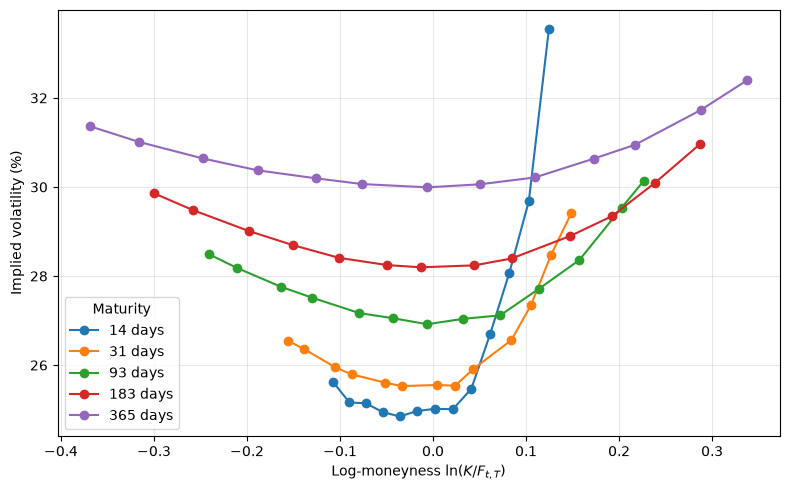

In [8]:
plt.figure(figsize=(8, 5))

for days, group in options.groupby("days"):
    group = group.sort_values("log_moneyness")
    plt.plot(
        group["log_moneyness"],
        100 * group["iv"],
        marker="o",
        label=f"{int(days)} days"
    )

plt.xlabel(r"Log-moneyness $\ln(K/F_{t,T})$")
plt.ylabel("Implied volatility (%)")
plt.legend(title="Maturity")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

We plot the IV per maturity and log-moneyness and observe various volatility smiles.

We notice that OTM call options are more expensive than a constant volatility Black-Scholes model would suggest. While a deep OTM call would indeed need a very large increase in price to have a positive payoff, BS assumes lognormally distributed returns which weights extreme scenarios less than we observe empirically. 

We also notice that the shorter the maturity, the higher the IV for OTM calls. For longer maturities this is best explained by e.g. volatility being stochastic and for very short maturities with very high IV this is best explained by jumps which can produce discontinuous price moves. If the market believes these models are more realistic it would show up as higher IV in the observed way.